<a href="https://colab.research.google.com/github/jaslindoniya/Feature-engineering-pipeline/blob/main/Feature_engineering_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
data = {
    'tenure_months': [2, 34, 5, 22, 3, 12, 1, 45, 8, 15, 4, 28, 6, 30],
    'support_tickets': [5, 0, 4, 1, 6, 2, 7, 0, 3, 1, 5, 0, 4, 1],
    'monthly_spend': [299, 999, 399, 799, 299, 499, 199, 1299, 399, 699, 299, 899, 349, 999],
    'last_login_days': [15, 2, 20, 5, 25, 8, 30, 1, 12, 4, 18, 3, 22, 2],
    'plan_type': ['Basic', 'Premium', 'Basic', 'Standard', 'Basic', 'Standard', 'Basic', 'Premium', 'Basic', 'Standard', 'Basic', 'Premium', 'Basic', 'Premium'],
    'contract_type': ['Monthly', 'Yearly', 'Monthly', 'Yearly', 'Monthly', 'Monthly', 'Monthly', 'Yearly', 'Monthly', 'Yearly', 'Monthly', 'Yearly', 'Monthly', 'Yearly'],
    'churned': [1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
}
df = pd.DataFrame(data)
print(df.head())

   tenure_months  support_tickets  monthly_spend  last_login_days plan_type  \
0              2                5            299               15     Basic   
1             34                0            999                2   Premium   
2              5                4            399               20     Basic   
3             22                1            799                5  Standard   
4              3                6            299               25     Basic   

  contract_type  churned  
0       Monthly        1  
1        Yearly        0  
2       Monthly        1  
3        Yearly        0  
4       Monthly        1  


In [8]:
X = df.drop('churned', axis=1)
y = df['churned']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

numeric_features = ['tenure_months', 'support_tickets', 'monthly_spend', 'last_login_days']
categorical_features = ['plan_type', 'contract_type']

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)
print("Leakage prevent pannitom! Split munnadi pannitom")

Train size: (9, 6)
Test size: (5, 6)
Leakage prevent pannitom! Split munnadi pannitom


In [9]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Success! Preprocessed shape:", X_train_processed.shape)
print(preprocessor.get_feature_names_out())

Success! Preprocessed shape: (9, 9)
['num__tenure_months' 'num__support_tickets' 'num__monthly_spend'
 'num__last_login_days' 'cat__plan_type_Basic' 'cat__plan_type_Premium'
 'cat__plan_type_Standard' 'cat__contract_type_Monthly'
 'cat__contract_type_Yearly']


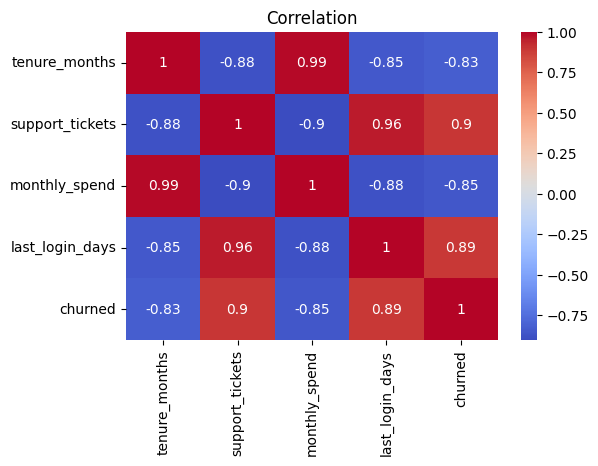

                      Feature  MI_Score
4        cat__plan_type_Basic  1.347487
7  cat__contract_type_Monthly  1.236376
0          num__tenure_months  0.671561
2          num__monthly_spend  0.597487
1        num__support_tickets  0.584524
3        num__last_login_days  0.528968
8   cat__contract_type_Yearly  0.486376
5      cat__plan_type_Premium  0.216799
6     cat__plan_type_Standard  0.035053
                      Feature  Importance
0          num__tenure_months    0.252525
1        num__support_tickets    0.171717
3        num__last_login_days    0.131313
7  cat__contract_type_Monthly    0.131313
2          num__monthly_spend    0.121212
8   cat__contract_type_Yearly    0.090909
4        cat__plan_type_Basic    0.080808
5      cat__plan_type_Premium    0.020202
6     cat__plan_type_Standard    0.000000


In [10]:
# Correlation
plt.figure(figsize=(6,4))
sns.heatmap(df[['tenure_months','support_tickets','monthly_spend','last_login_days','churned']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation")
plt.show()

# Feature Importance
feature_names = preprocessor.get_feature_names_out()
mi_scores = mutual_info_classif(X_train_processed, y_train)
mi_df = pd.DataFrame({'Feature': feature_names, 'MI_Score': mi_scores}).sort_values('MI_Score', ascending=False)
print(mi_df)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_processed, y_train)
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': rf.feature_importances_}).sort_values('Importance', ascending=False)
print(importance_df)